In [66]:
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

#Limites maximos de las coordenadas de los rectangulos
MAX_X = 100
MAX_ALTURA = 50
MIN_ANCHO = 5
MAX_ANCHO = 25

In [67]:
def crear_rectangulos():
    rectangulos = []

    cantidad = int(input("¿Cuántos rectángulos deseas generar? "))

    for _ in range(cantidad):
        # Generar coordenadas aleatorias
        izquierda = random.randint(0, MAX_X - MIN_ANCHO)
        ancho = random.randint(MIN_ANCHO, MAX_ANCHO)

        # Evitar que la coordenada derecha exceda MAX_X
        derecha = min(izquierda + ancho, MAX_X)

        altura = random.randint(1, MAX_ALTURA)

        # Guardar la tripleta (izquierda, altura, derecha)
        rectangulos.append((izquierda, altura, derecha))

    return rectangulos

In [68]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def dibujar_rectangulos(rectangulos):
    if not rectangulos:
        print("No hay rectángulos para dibujar.")
        return

    fig, ax = plt.subplots(figsize=(12, 6))

    for izquierda, altura, derecha in rectangulos:
        ancho = derecha - izquierda

        rectangulo = Rectangle(
            (izquierda, 0),
            ancho,
            altura,
            facecolor="skyblue",
            edgecolor="blue",
            alpha=0.45,
            linewidth=1.5
        )

        ax.add_patch(rectangulo)

    # Calcular los límites a partir de los rectángulos
    min_x = min(r[0] for r in rectangulos)
    max_x = max(r[2] for r in rectangulos)
    max_altura = max(r[1] for r in rectangulos)

    # Añadir un margen del 5 % en X y del 15 % en Y
    margen_x = (max_x - min_x) * 0.05
    margen_y = max_altura * 0.15

    # Evitar márgenes nulos
    margen_x = max(margen_x, 0.5)
    margen_y = max(margen_y, 0.5)

    ax.set_xlim(min_x - margen_x, max_x + margen_x)
    ax.set_ylim(0, max_altura + margen_y)

    # Configurar el plano cartesiano
    ax.set_xlabel("Coordenada X")
    ax.set_ylabel("Altura (Y)")
    ax.set_title("Rectángulos generados aleatoriamente")

    ax.axhline(y=0, color="black", linewidth=1)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    plt.show()

In [69]:
def dibujar_contorno(franjas):
    if not franjas:
        print("No hay franjas para dibujar.")
        return

    # Ordenar las franjas por coordenada izquierda
    franjas = sorted(franjas, key=lambda f: f[0])

    # Calcular los límites de las coordenadas
    min_x = min(f[0] for f in franjas)
    max_x = max(f[0] for f in franjas)
    max_altura = max(f[1] for f in franjas)

    # Calcular los márgenes
    margen_x = max((max_x - min_x) * 0.05, 0.5)
    margen_y = max(max_altura * 0.15, 0.5)

    # Crear un espacio de dibujo independiente
    fig, ax = plt.subplots(figsize=(12, 6))

    for izquierda, altura in franjas:
        # Todas las franjas tienen ancho fijo de 1 unidad
        ancho = 1

        if altura > 0:
            franja = Rectangle(
                (izquierda, 0),
                ancho,
                altura,
                facecolor="salmon",
                edgecolor="red",
                alpha=0.5,
                linewidth=1.5
            )

            ax.add_patch(franja)

    # Ajustar los límites para incluir la última franja y sus márgenes
    limite_izquierdo = min_x - margen_x
    limite_derecho = max_x + 1 + margen_x

    ax.set_xlim(limite_izquierdo, limite_derecho)
    ax.set_ylim(0, max_altura + margen_y)

    # Configurar etiquetas y presentación
    ax.set_xlabel("Coordenada X")
    ax.set_ylabel("Altura (Y)")
    ax.set_title("Contorno formado por franjas")

    ax.axhline(y=0, color="black", linewidth=1)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)

    plt.show()

In [70]:
#Algoritmo fuerza bruta
def fuerzaBruta(rectangulos):
    # Crear un diccionario para almacenar la altura máxima en cada coordenada X
    alturas = {}

    # Iterar sobre cada rectángulo
    for izquierda, altura, derecha in rectangulos:
        # Actualizar la altura máxima para cada coordenada X cubierta por el rectángulo
        for x in range(izquierda, derecha):
            if x in alturas:
                alturas[x] = max(alturas[x], altura)
            else:
                alturas[x] = altura

    # Convertir el diccionario de alturas en una lista de franjas (izquierda, altura)
    franjas = sorted(alturas.items())

    return franjas


Tripletas almacenadas:
[(24, 38, 47), (77, 25, 87), (90, 20, 100), (58, 26, 79), (80, 46, 98)]

Franjas generadas por el algoritmo de fuerza bruta:
[(24, 38), (25, 38), (26, 38), (27, 38), (28, 38), (29, 38), (30, 38), (31, 38), (32, 38), (33, 38), (34, 38), (35, 38), (36, 38), (37, 38), (38, 38), (39, 38), (40, 38), (41, 38), (42, 38), (43, 38), (44, 38), (45, 38), (46, 38), (58, 26), (59, 26), (60, 26), (61, 26), (62, 26), (63, 26), (64, 26), (65, 26), (66, 26), (67, 26), (68, 26), (69, 26), (70, 26), (71, 26), (72, 26), (73, 26), (74, 26), (75, 26), (76, 26), (77, 26), (78, 26), (79, 25), (80, 46), (81, 46), (82, 46), (83, 46), (84, 46), (85, 46), (86, 46), (87, 46), (88, 46), (89, 46), (90, 46), (91, 46), (92, 46), (93, 46), (94, 46), (95, 46), (96, 46), (97, 46), (98, 20), (99, 20)]


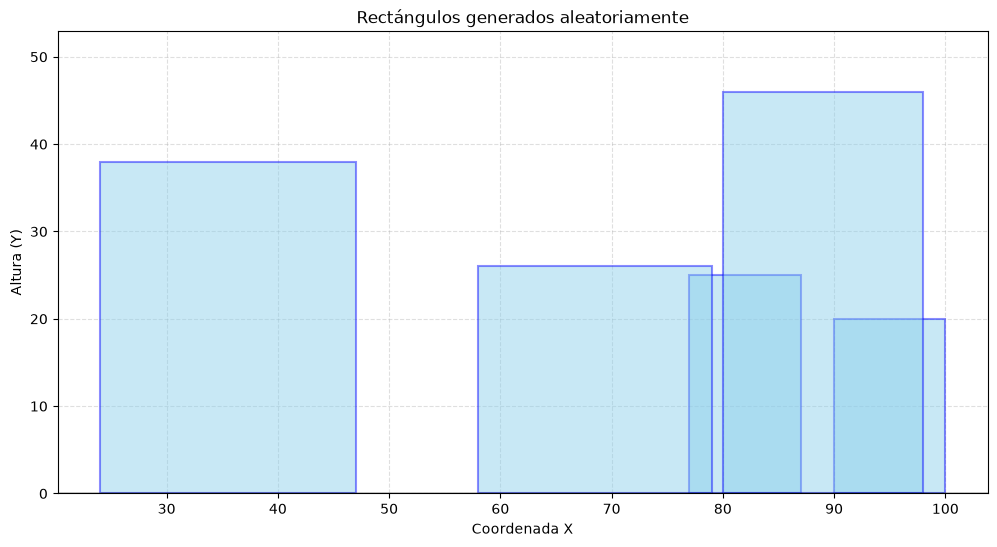

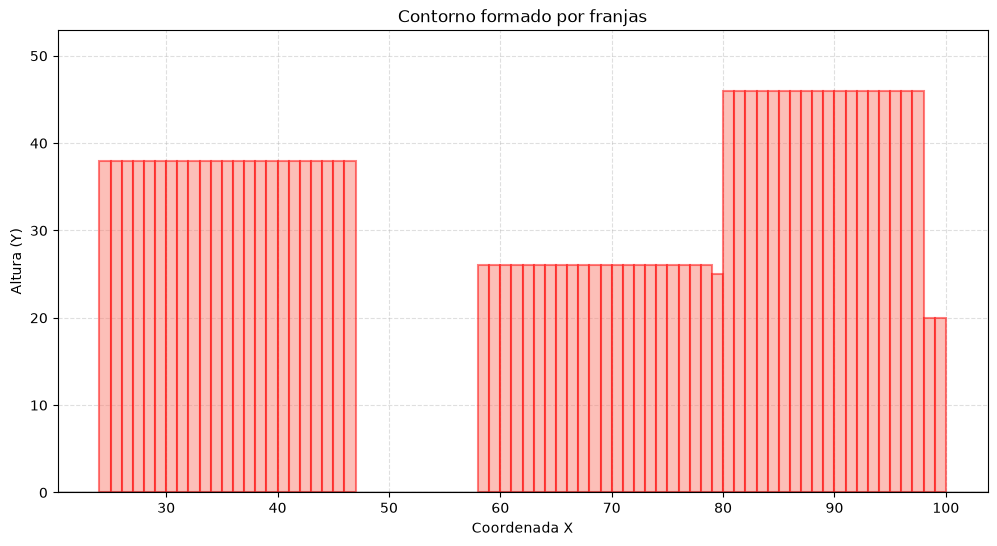

In [71]:
# Crear y almacenar las tripletas
rectangulos = crear_rectangulos()
franjas = fuerzaBruta(rectangulos)

#datos de prueba
#rectangulos = [(1,11,5), (2,6,7), (3,13,9), (12,7,16), (14,3,25), (19,18,22)]
#franjas = [(1,11), (3,13), (9,0), (12,7), (16,3), (19,18), (22,3), (25,0)]

# Mostrar las tripletas ingresadas
print("\nTripletas almacenadas:")
print(rectangulos)

print("\nFranjas generadas por el algoritmo de fuerza bruta:")
print(franjas)

# Dibujar los rectángulos
dibujar_rectangulos(rectangulos)
dibujar_contorno(franjas)